In [4]:
import io
import re
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from Bio.KEGG import REST
from Bio.KEGG.KGML import KGML_parser
from IPython.display import Image, display

base_dir = Path.cwd().parent
processed_dir = base_dir / "data" / "processed"
fig_dir = base_dir / "results" / "images"
fig_dir.mkdir(parents=True, exist_ok=True)

# Uso de KEGG para buscar imágenes relevantes de COVID-19

In [44]:
# Lista de todas las vías de KEGG: cada línea es "map05171<TAB>Coronavirus disease - COVID-19".
resultado = REST.kegg_list("pathway").read()

# Nos quedamos con las vías que mencionan coronavirus: {id: descripción}.
covid_output = {}
for line in resultado.strip().splitlines():
    kegg_id, description = line.split("\t")
    if "coronavirus" in description.lower():
        covid_output[kegg_id.replace("path:", "")] = description
print(covid_output)

# Descarga la imagen del virión (vía map03262).
for kegg_id, description in covid_output.items():
    if "virion" in description.lower():
        ruta = fig_dir / f"{kegg_id}_covid_virion.png"
        virion_image = REST.kegg_get(kegg_id, "image").read()
        with open(ruta, "wb") as f:
            f.write(virion_image)
        print("Se guardó la imagen del virión en:", ruta)

{'map03262': 'Virion - Coronavirus', 'map05171': 'Coronavirus disease'}
Se guardó la imagen del virión en: c:\Users\cecil\OneDrive\Documents\GitHub\analisis_var_gene\results\images\map03262_covid_virion.png


In [5]:
# Coordenadas nt de cada nsp dentro de ORF1ab (Tabla 1, PMC9794616; NC_045512.2).
# KEGG dibuja cada nsp como una caja aparte, así que ORF1a/ORF1b se traducen a nsp.
nsp_positions = {
    "nsp1": (266, 805),       "nsp2": (806, 2719),      "nsp3": (2720, 8554),
    "nsp4": (8555, 10054),    "nsp5": (10055, 10972),   "nsp6": (10973, 11842),
    "nsp7": (11843, 12091),   "nsp8": (12092, 12685),   "nsp9": (12686, 13024),
    "nsp10": (13025, 13441),  "nsp12": (13442, 16236),  "nsp13": (16237, 18039),
    "nsp14": (18040, 19620),  "nsp15": (19621, 20658),  "nsp16": (20659, 21552),
}

# Inicio de ORF1a y ORF1b en el GFF3: sirve para pasar de codón a la posición medida en nucleótidos.
orf_starts = {"ORF1a": 266, "ORF1b": 13468}


def aa_a_proteina(aa_mutation):
    """
    Devuelve la proteína madura de una mutación de aminoácido de Nextclade.

    Parámetros
    ----------
    aa_mutation : str
        Mutación en formato de Nextclade, p. ej. "ORF1a:T3255I" o "S:D614G".

    Devuelve
    --------
    str
        El nsp si el gen es ORF1a/ORF1b (p. ej. "nsp4"); en otro caso, el mismo gen.
    """
    gen, cambio = aa_mutation.split(":")
    if gen in orf_starts:
        codon = int(re.search(r"\d+", cambio).group())        # "T3255I" -> 3255
        posicion = orf_starts[gen] + 3 * (codon - 1)          # primer nt de ese codón
        for nsp, (inicio, fin) in nsp_positions.items():
            if inicio <= posicion <= fin:
                return nsp
    return gen


def mutaciones_aa_por_proteina(ruta_mutaciones):
    """
    Cuenta mutaciones de aminoácido únicas por proteína, juntando todos los años.

    Parámetros
    ----------
    ruta_mutaciones : Path
        Tabla de frecuencias aa por año (columna aa_mutation).

    Devuelve
    --------
    dict
        {proteína: número de mutaciones de aa únicas}.
    """
    try:
        df = pd.read_csv(ruta_mutaciones, sep="\t")
    except FileNotFoundError:
        raise FileNotFoundError(f"No existe {ruta_mutaciones}: corre primero el notebook de frecuencias.")

    conteo = {}
    for mutacion in df["aa_mutation"].unique():               # cada mutación de aa una sola vez
        proteina = aa_a_proteina(mutacion)
        conteo[proteina] = conteo.get(proteina, 0) + 1
    return conteo


conteo = mutaciones_aa_por_proteina(processed_dir / "nuevas_frecuencias_aa_por_anio.tsv")

mayor = max(conteo, key=conteo.get)
print(f"La proteína {mayor} tuvo ({conteo[mayor]}) mutaciones únicas de aminoácidos, así que fue la más afectada.")

La proteína S tuvo (224) mutaciones únicas de aminoácidos, así que fue la más afectada.


# Gráfica de barras

In [6]:
# Límite superior de cada nivel (mutaciones únicas) y su color.
level_limits = {"bajo": 56, "medio": 112, "alto": 168, "muy alto": float("inf")}
level_colors = {"bajo": "#6baed6", "medio": "#2171b5", "alto": "#08306b", "muy alto": "#9A1EC7"}


def assign_levels(counts):
    """
    Asigna a cada proteína un nivel (bajo, medio, alto o muy alto) y un color
    según su número de mutaciones únicas.

    Parámetros
    ----------
    counts : dict o pd.Series
        {proteína: número de mutaciones únicas}.

    Devuelve
    --------
    dict
        {proteína: {"mutations": n, "level": nivel, "color": color}}.
    """
    proteins = {}
    for protein, value in counts.items():
        try:
            n = int(value)
        except (TypeError, ValueError):
            print(f"Aviso: valor no numérico para {protein} ({value}), se omite.")
            continue
        for level, limit in level_limits.items():       # el primer límite que no se rebasa
            if n <= limit:
                break
        proteins[protein] = {"mutations": n, "level": level, "color": level_colors[level]}
    return proteins


def plot_mutations_by_protein(proteins, file_name="mutaciones_por_proteina.png"):
    """
    Grafica barras horizontales con las mutaciones únicas por proteína, coloreadas
    según su nivel y con el total escrito al final de cada barra.

    Parámetros
    ----------
    proteins : dict
        Salida de assign_levels: {proteína: {"mutations", "level", "color"}}.
    file_name : str, opcional
        Nombre del archivo que se guarda en fig_dir.

    Devuelve
    --------
    None
    """
    if not proteins:
        raise ValueError("No hay proteínas para graficar.")
    try:
        ordered = sorted(proteins, key=lambda p: proteins[p]["mutations"])
        values = [proteins[p]["mutations"] for p in ordered]
        colors = [proteins[p]["color"] for p in ordered]
    except KeyError as error:
        raise KeyError(f"A una proteína le falta la clave {error}. Verifica que hayas usado la función assign_levels?")

    fig, ax = plt.subplots(figsize=(5, 0.22 * len(ordered) + 1))  
    bars = ax.barh(ordered, values, color=colors, height=0.75)      
    ax.bar_label(bars, padding=2, fontsize=7)                       # Se añade el total de mutaciones al final de cada barra.
    ax.set_xlim(0, max(values) * 1.1)                              
    ax.margins(y=0.01)                                              
    ax.tick_params(axis="y", labelsize=8, length=0)                
    ax.tick_params(axis="x", labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)                  

    present = {proteins[p]["level"] for p in ordered}
    ax.legend(handles=[Patch(color=level_colors[level], label=level)
                       for level in level_limits if level in present],
              title="Nivel", loc="lower right", fontsize=8, title_fontsize=8, frameon=False)
    ax.set_xlabel("Mutaciones")
    ax.set_ylabel("Proteína")
    ax.set_title("Mutaciones no sinónimas únicas por proteína (2020–2024)")
    fig.tight_layout()

    ruta = fig_dir / file_name
    try:
        fig.savefig(ruta, dpi=300)
        print("Se guardó la gráfica en:", ruta)
    except OSError as error:
        print(f"No se pudo guardar {ruta}:", error)
    finally:
        plt.show()
        plt.close(fig)

Se guardó la gráfica en: c:\Users\cecil\OneDrive\Documents\GitHub\analisis_var_gene\results\images\mutaciones_por_proteina.png


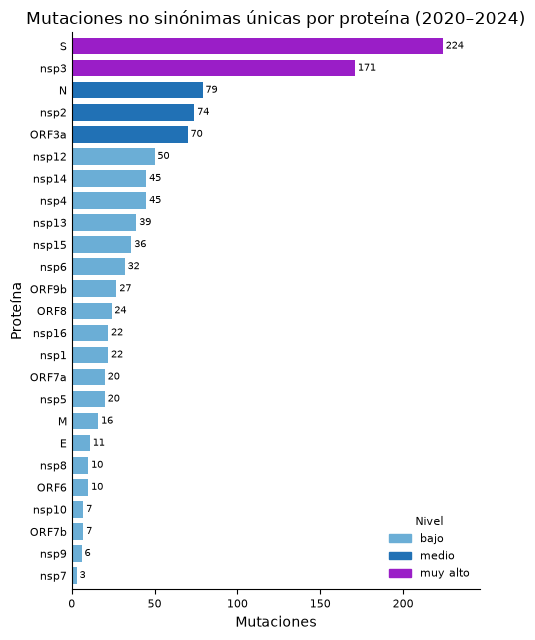

In [7]:
proteins = assign_levels(conteo)       # conteo = {proteína: mutaciones únicas}
plot_mutations_by_protein(proteins)

## Relacionar las proteínas identificadas con el esquema de KEGG

KEGG no rotula las cajas del mapa con nombres de proteína, sino con **identificadores KO** (KEGG Orthology), p. ej. `K24152` es la proteína S. Para saber qué caja corresponde a cada una de nuestras proteínas se hace:

1. **Descargar el mapa** como imagen (PNG) y como **KGML**, un XML que lista cada caja con su KO y sus coordenadas en la imagen. Solo los mapas `ko05171` tienen KGML (los `map05171` no).
2. **Traducir KO → nombre**: se le pregunta a KEGG la descripción de cada KO (`K24152` → `"S; spike glycoprotein"`) y se toma el nombre antes del `;`.
3. **Comparar** esos nombres con las proteínas de `conteo` (en mayúsculas, para que `nsp12` y `NSP12` coincidan).
4. **Dibujar un rectángulo** sobre cada caja que coincidió, usando sus coordenadas del KGML.

Encontrados: ['E', 'M', 'N', 'NSP1', 'NSP10', 'NSP12', 'NSP13', 'NSP14', 'NSP15', 'NSP16', 'NSP2', 'NSP3', 'NSP4', 'NSP5', 'NSP6', 'NSP7', 'NSP8', 'NSP9', 'S']
No encontrados: ['ORF3A', 'ORF6', 'ORF7A', 'ORF7B', 'ORF8', 'ORF9B']
Mapa guardado en c:\Users\cecil\OneDrive\Documents\GitHub\analisis_var_gene\results\images\ko05171_mutaciones.png


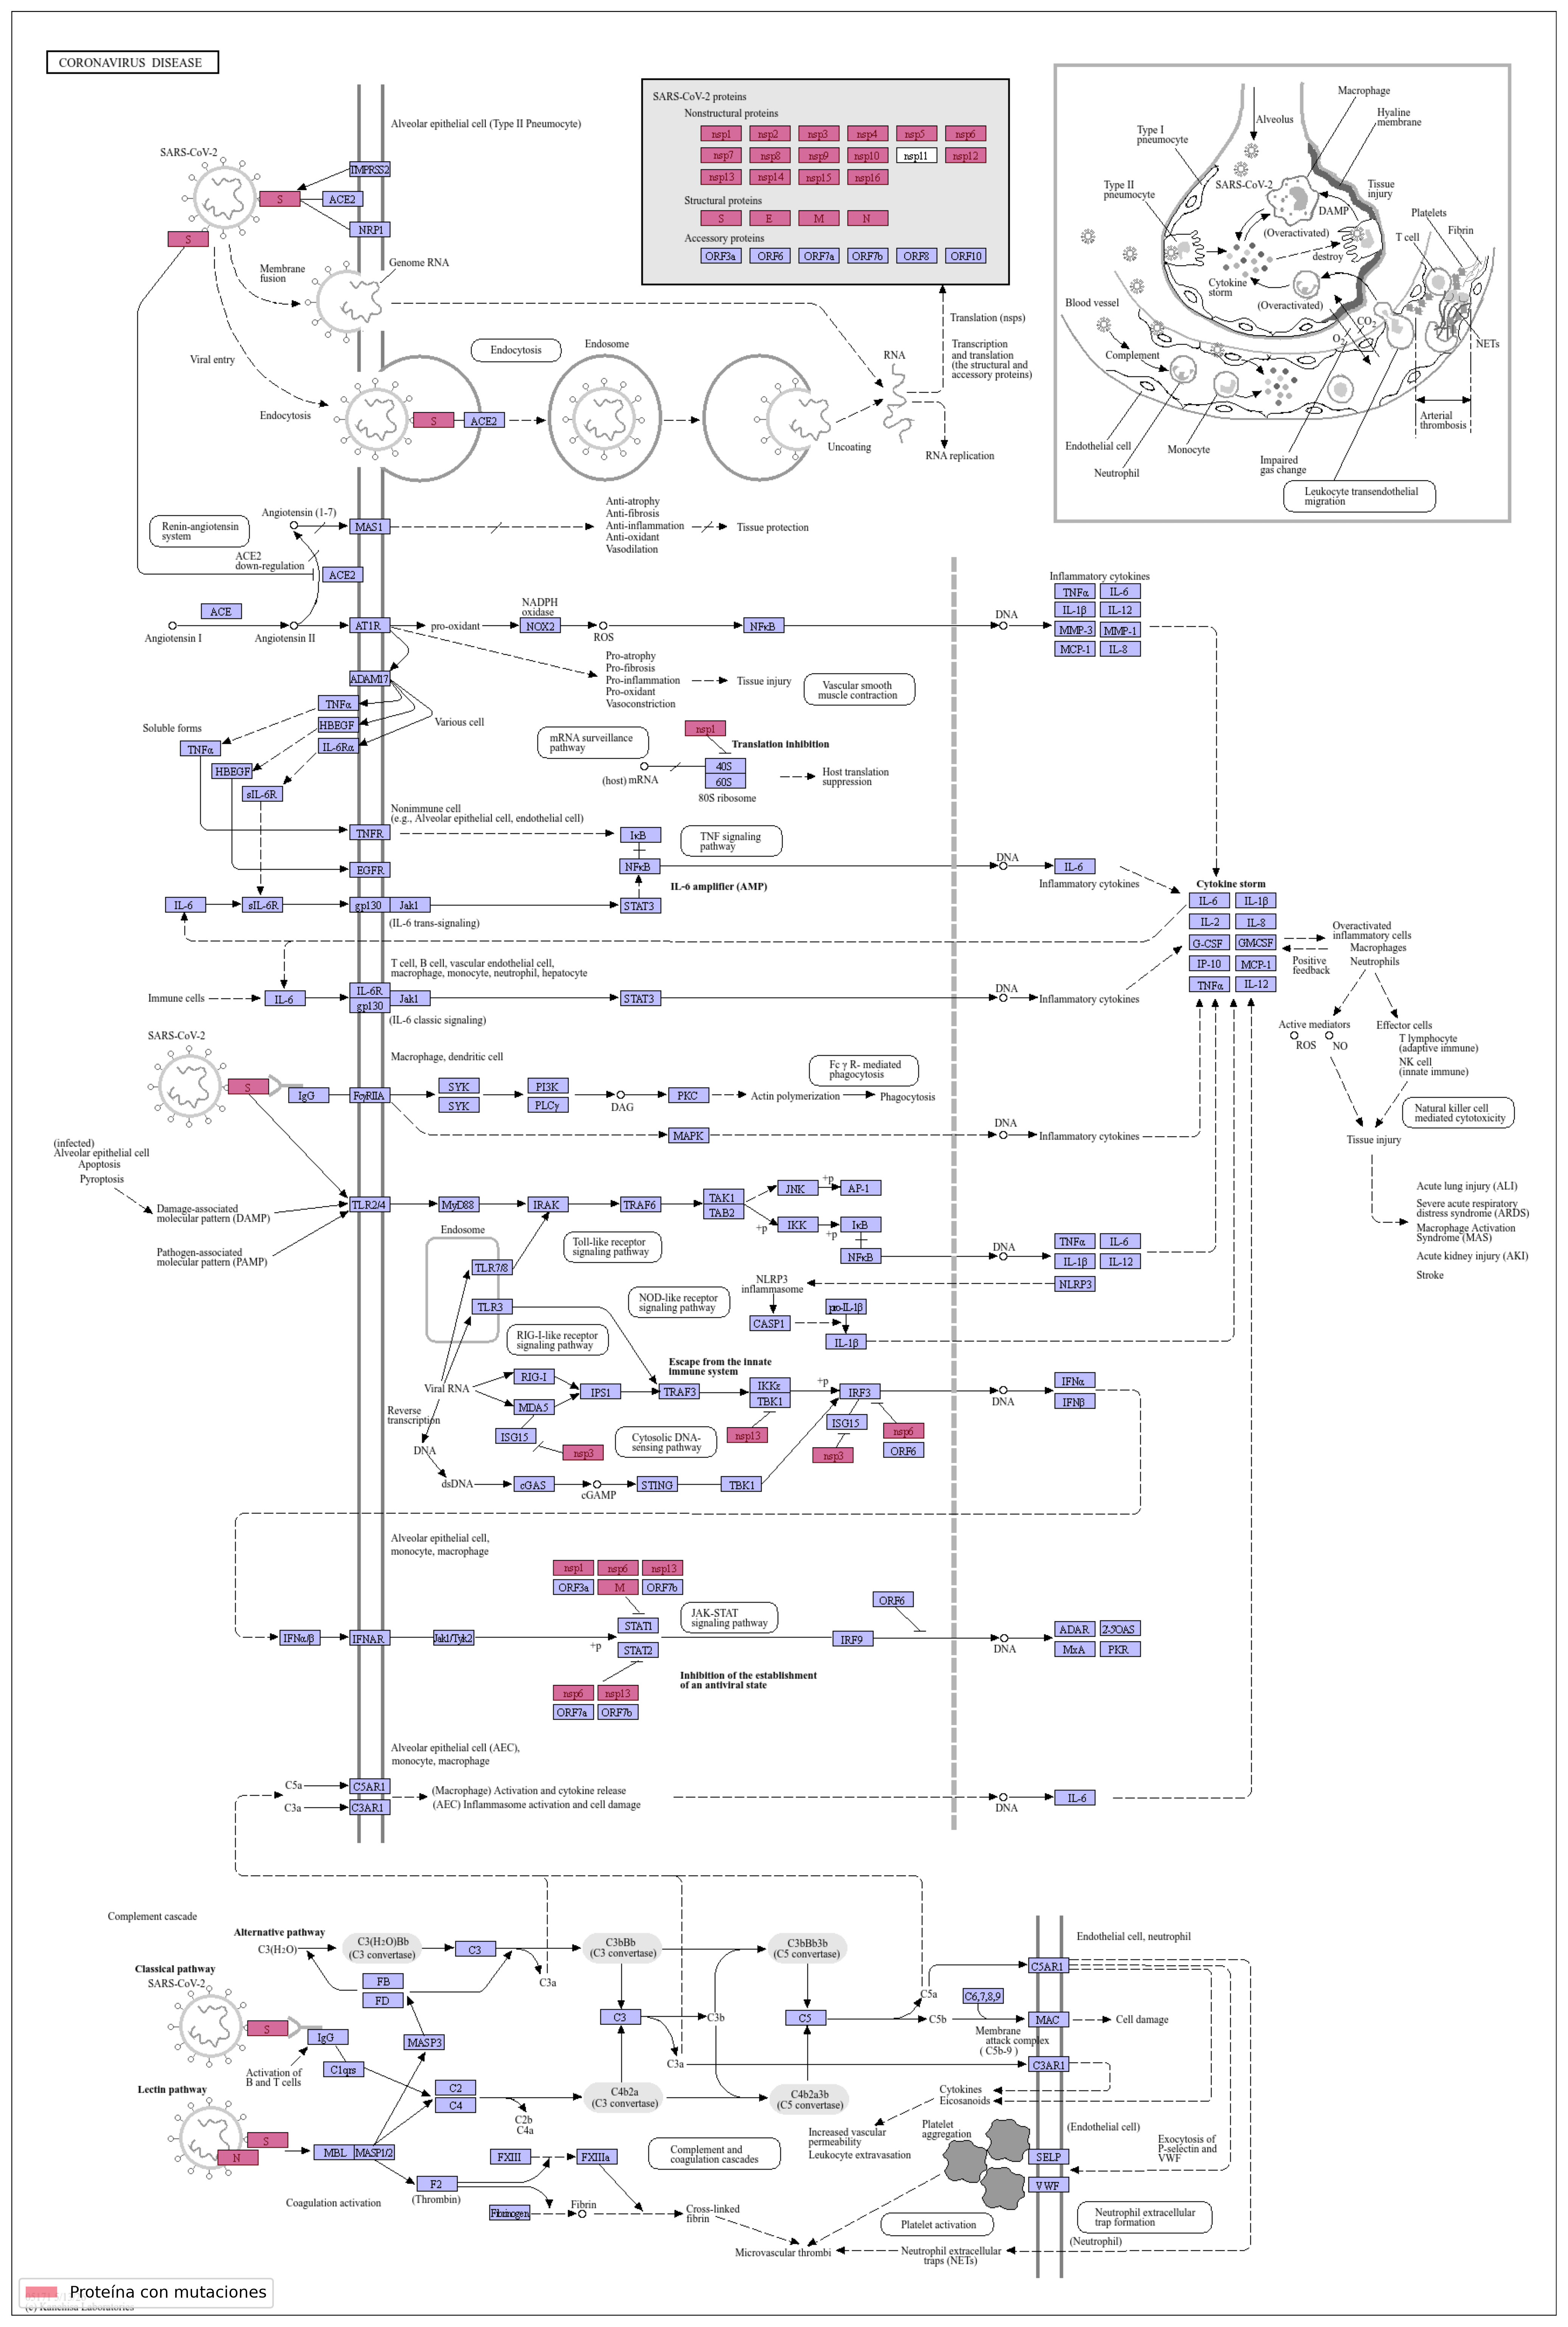

In [ ]:
def simbolos_de_kos(kos):
    """
    Pregunta a KEGG el nombre (símbolo) de cada identificador KO.

    Parámetros
    ----------
    kos : iterable de str
        Identificadores KO sin prefijo, p. ej. {"K24152", "K24153"}.

    Devuelve
    --------
    dict
        {KO: [símbolos en mayúsculas]}, p. ej. {"K24152": ["S"]}.
    """
    simbolos = {}
    kos = sorted(kos)
    for i in range(0, len(kos), 10):                     # de 10 en 10: KEGG limita cuántos acepta por consulta
        bloque = ["ko:" + k for k in kos[i:i + 10]]
        texto = REST.kegg_list(bloque).read()            # una línea por KO: "ko:K24152<TAB>S; spike glycoprotein"
        for linea in texto.strip().splitlines():
            ko, descripcion = linea.split("\t", 1)
            ko = ko.replace("ko:", "")
            parte_simbolos = descripcion.split(";")[0]   # lo que va antes del ";" es el nombre corto: "S"
            # Algunos KO tienen alias separados por coma ("nsp12, RdRp"): se guardan todos.
            simbolos[ko] = [s.strip().upper() for s in parte_simbolos.split(",")]
    return simbolos


def colorear_mapa(map_id, proteinas, carpeta_salida=fig_dir, color="#ea1938"):
    """
    Resalta en un mapa de KEGG las cajas de las proteínas que tuvieron mutaciones.

    Parámetros
    ----------
    map_id : str
        Identificador del mapa, p. ej. "map05171".
    proteinas : iterable de str
        Nombres de las proteínas con mutaciones (p. ej. las llaves de conteo).
    carpeta_salida : Path, opcional
        Carpeta donde se guarda la imagen (fig_dir por defecto).
    color : str, opcional
        Color de los rectángulos.

    Devuelve
    --------
    tuple
        (ruta de la imagen guardada o None, {KO: [símbolos]} de todas las cajas del mapa).
    """
    buscadas = {p.upper() for p in proteinas}            # mayúsculas para comparar con los símbolos de KEGG
    pathway_id = "ko" + map_id.replace("map", "")        # 'map05171' -> 'ko05171' (solo 'ko' tiene KGML)

    # 1) Imagen del mapa y su KGML (XML con cada caja: tipo, KO y coordenadas).
    png = REST.kegg_get(pathway_id, "image").read()
    imagen = plt.imread(io.BytesIO(png))
    kgml = REST.kegg_get(pathway_id, "kgml").read()
    pathway = KGML_parser.read(io.StringIO(kgml))

    # 2) Juntar los KO de todas las cajas de proteína ("ortholog") y traducirlos a nombres.
    kos_del_mapa = set()
    for entrada in pathway.entries.values():
        if entrada.type == "ortholog":
            for nombre in entrada.name.split():          # una caja puede tener varios KO: "ko:K24152 ko:K24153"
                kos_del_mapa.add(nombre.replace("ko:", ""))
    simbolos = simbolos_de_kos(kos_del_mapa)

    # 3) Dibujar el mapa y colorear las cajas cuyo nombre esté entre nuestras proteínas.
    alto, ancho = imagen.shape[0], imagen.shape[1]
    fig, ax = plt.subplots(figsize=(ancho / 100, alto / 100), dpi=100)
    ax.imshow(imagen)                                    # mismas coordenadas en píxeles que el KGML
    ax.axis("off")

    encontrados = set()
    for entrada in pathway.entries.values():
        if entrada.type != "ortholog":
            continue
        coincidencias = set()
        for nombre in entrada.name.split():
            ko = nombre.replace("ko:", "")
            # Intersección: nombres de este KO que también están en nuestras proteínas.
            coincidencias.update(set(simbolos.get(ko, [])) & buscadas)
        if coincidencias:
            for g in entrada.graphics:
                # El KGML da el centro (x, y) de la caja; Rectangle pide la esquina superior izquierda.
                ax.add_patch(Rectangle((g.x - g.width / 2, g.y - g.height / 2), g.width, g.height,
                                       facecolor=color, alpha=0.5, edgecolor="none"))
            encontrados.update(coincidencias)

    print("Encontrados:", sorted(encontrados))
    print("No encontrados:", sorted(buscadas - encontrados))

    # 4) Leyenda y guardado (solo si se coloreó algo).
    salida = None
    if encontrados:
        ax.legend(handles=[Patch(facecolor=color, alpha=0.5, label="Proteína con mutaciones")],
                  loc="lower left")
        salida = Path(carpeta_salida) / f"{pathway_id}_mutaciones_por_cambio_aa.png"
        fig.savefig(salida, dpi=300, bbox_inches="tight")
        print("Mapa guardado en", salida)
    plt.close(fig)
    return salida, simbolos


for kegg_id, description in covid_output.items():
    if "disease" in description.lower():
        salida, simbolos = colorear_mapa(kegg_id, conteo.keys())
        if salida:
            display(Image(filename=str(salida), width=900))